In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [127]:
obs_file = '../../dev/CAMP2Ex_RF17_MISR_OBS_002.nc'
obs = xr.load_dataset(obs_file, engine='netcdf4')

bulk_props_file = '../../data/CAMP2Ex_SPEC/CAMP2Ex-CloudBulkProps_P3B_20191001_R0.ICT'
nav_file = '../../data/CAMP2Ex_SPEC/CAMP2EX-MetNav_P3B_20191001_R0.ict'
bulk_props = pd.read_csv(bulk_props_file, skiprows=37, header=0, index_col=0)
nav = pd.read_csv(nav_file, skiprows=73, header=0, index_col=0)
bulk_props.index = pd.to_datetime(bulk_props.index, unit='s', origin=pd.Timestamp('2019-10-01'))
bulk_props.index.name = 'time'
bulk_props = bulk_props.to_xarray()
nav.index = pd.to_datetime(nav.index, unit='s', origin=pd.Timestamp('2019-10-01'))
nav.index.name = 'time'
nav = nav.to_xarray()
data = xr.merge([bulk_props, nav])
nan_reff = data.Reff_um.copy(deep=True).data
nan_reff[nan_reff == 0] = np.nan
data['Reff_um'] = (['time'], nan_reff)
data = data.sel(time=slice('2019-10-02T01:30:00', '2019-10-02T01:50:00'))

In [128]:
def plot_time_point(data, time, ax, color='tab:orange'):
    tmp_data = data.sel(time=time).copy(deep=True)
    c = ax.scatter(tmp_data.Longitude.data, tmp_data.Latitude.data, s=20, marker='*', c=color, label=time)

(19.5, 20.3)

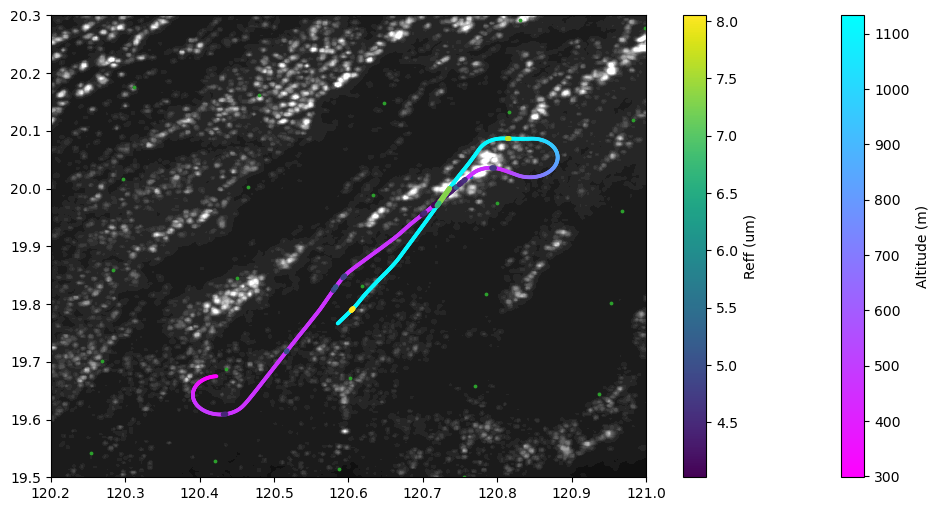

In [137]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.35, cmap='gray', levels=100)
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(120.7646, 20.0208, s=3, marker='*')
c1 = ax.scatter(data.Longitude.data, data.Latitude.data, s=3, alpha=1.0, c=data.GPS_Altitude.data, cmap='cool_r')
# c1 = ax.scatter(data.Longitude.data, data.Latitude.data, s=7, alpha=1.0, c=data.time.data, cmap='cool_r')
c2 = ax.scatter(data.Longitude.data, data.Latitude.data, s=7, alpha=1.0, c=data.Reff_um.data)
plt.colorbar(c1, label='Altitude (m)')
plt.colorbar(c2, label='Reff (um)')
# plot_time_point(data, '2019-10-02T01:35:49', ax, color='cyan')
# plot_time_point(data, '2019-10-02T01:36:22', ax, color='cyan')
# plot_time_point(data, '2019-10-02T01:38:39', ax, color='lime')
# plot_time_point(data, '2019-10-02T01:39:35', ax, color='lime')
# plot_time_point(data, '2019-10-02T01:40:01', ax, color='lime')
# plot_time_point(data, '2019-10-02T01:40:36', ax, color='yellow')
# plot_time_point(data, '2019-10-02T01:40:41', ax, color='yellow')
# plot_time_point(data, '2019-10-02T01:43:33', ax, color='yellow')
# plot_time_point(data, '2019-10-02T01:43:36', ax, color='yellow')
# plot_time_point(data, '2019-10-02T01:45:28', ax, color='red')
# plot_time_point(data, '2019-10-02T01:46:05', ax, color='red')
# plot_time_point(data, '2019-10-02T01:49:27', ax, color='orange')
# plot_time_point(data, '2019-10-02T01:49:32', ax, color='orange')
# plot_time_point(data, '2019-10-02T01:57:32', ax, color='orange')
# ax.scatter(119.7243, 19.2663, s=17, marker='*', color='cyan', label='RF17a')
# ax.set_xlim([118, 123])
# ax.set_ylim([17.4, 21.5])
# ax.legend()
# ax.set_xlim([119.8, 121.0])
# ax.set_ylim([18.4, 20.3])
ax.set_xlim([120.2, 121.0])
ax.set_ylim([19.5, 20.3])

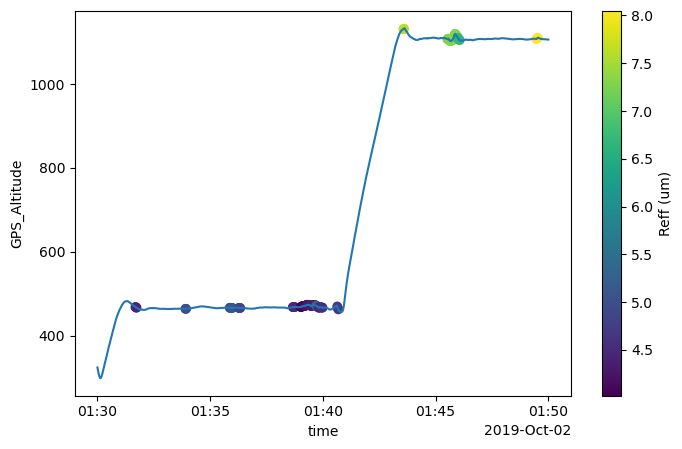

In [131]:
f, ax = plt.subplots(1, 1, figsize=(8,5))
data.GPS_Altitude.plot(ax=ax)
c = ax.scatter(data.time.data, data.GPS_Altitude.data, c=data.Reff_um.data)
# ax.vlines(['2019-10-02T00:20:00', '2019-10-02T00:50:00'], [0, 0], [1700, 1700], colors='red')
plt.colorbar(c, ax=ax, label='Reff (um)')


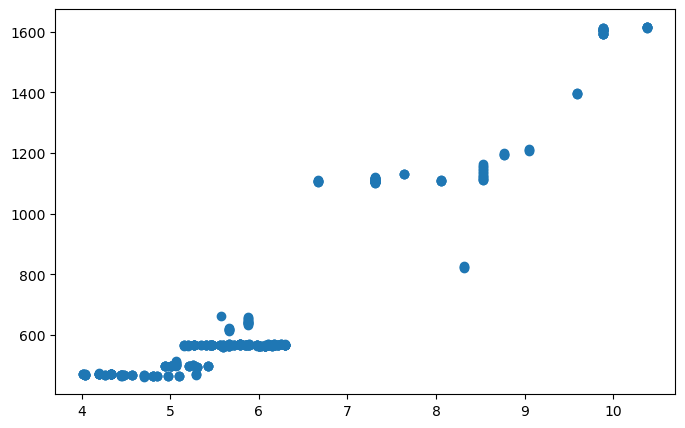

In [94]:
f, ax = plt.subplots(1, 1, figsize=(8,5))
ax.scatter(data.Reff_um.data, data.GPS_Altitude.data)